<a href="https://colab.research.google.com/github/JosephAt10/PCVK_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#import library yang dibutuhkan
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [4]:
#akses drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


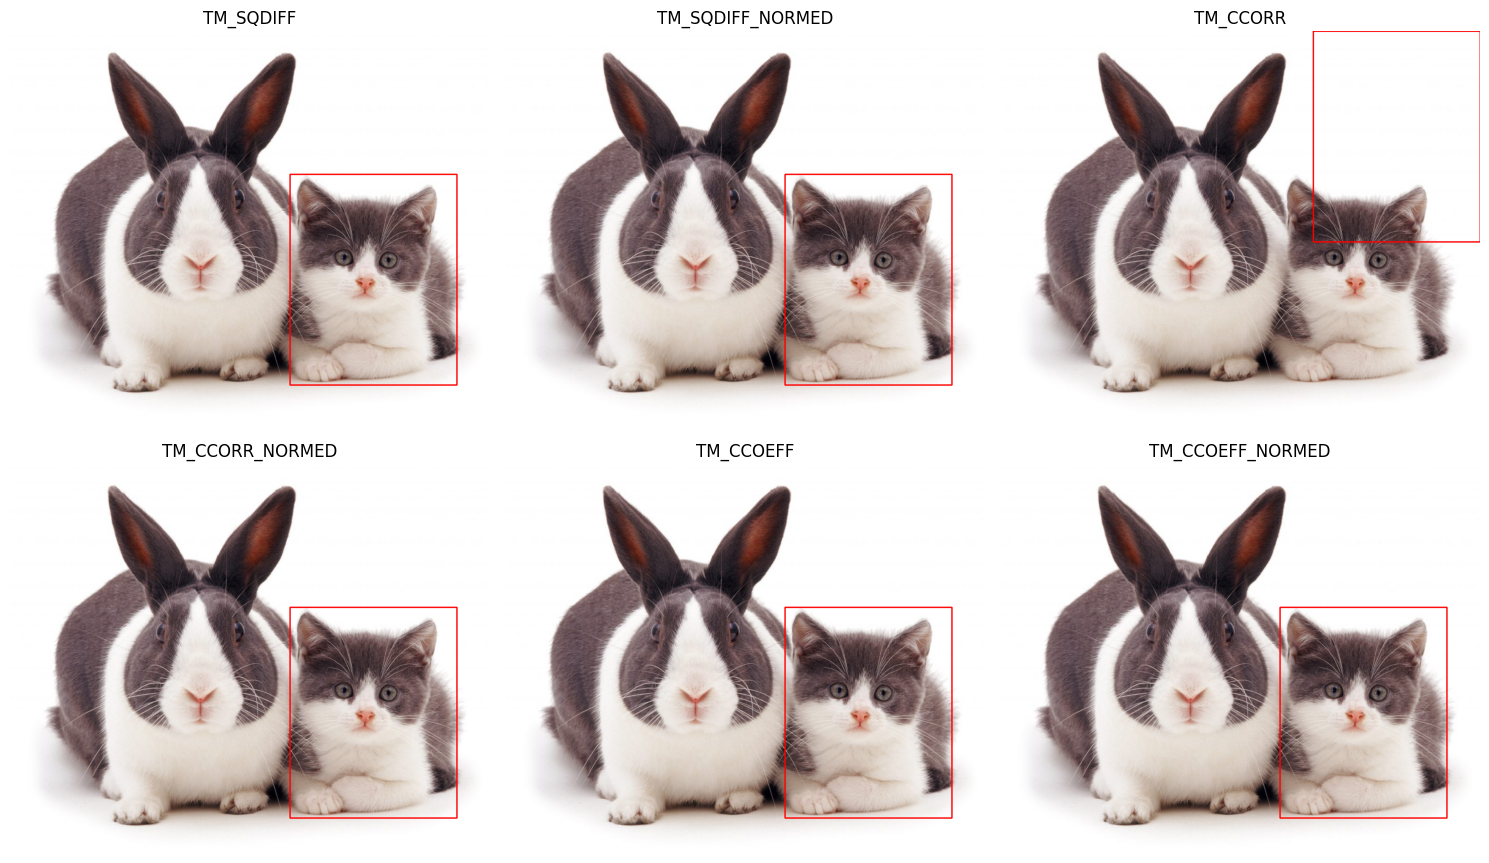

In [5]:
source_path = "/content/drive/MyDrive/PCVK_2026/Images/cats_and_bunnies.jpg"
template_path = "/content/drive/MyDrive/PCVK_2026/Images/cat2_templatejpg.jpg"

source = cv.imread(source_path)
template = cv.imread(template_path)

if source is None:
    raise FileNotFoundError(source_path)
if template is None:
    raise FileNotFoundError(template_path)

source_gray = cv.cvtColor(source, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
h, w = template_gray.shape

methods = [
    ("TM_SQDIFF", cv.TM_SQDIFF),
    ("TM_SQDIFF_NORMED", cv.TM_SQDIFF_NORMED),
    ("TM_CCORR", cv.TM_CCORR),
    ("TM_CCORR_NORMED", cv.TM_CCORR_NORMED),
    ("TM_CCOEFF", cv.TM_CCOEFF),
    ("TM_CCOEFF_NORMED", cv.TM_CCOEFF_NORMED),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (method_name, method) in zip(axes.flat, methods):
    result = cv.matchTemplate(source_gray, template_gray, method)
    min_value, max_value, min_location, max_location = cv.minMaxLoc(result)

    location = (
        min_location
        if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED)
        else max_location
    )

    result_image = source.copy()
    cv.rectangle(
        result_image,
        location,
        (location[0] + w, location[1] + h),
        (0, 0, 255),
        2,
    )

    ax.imshow(cv.cvtColor(result_image, cv.COLOR_BGR2RGB))
    ax.set_title(method_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

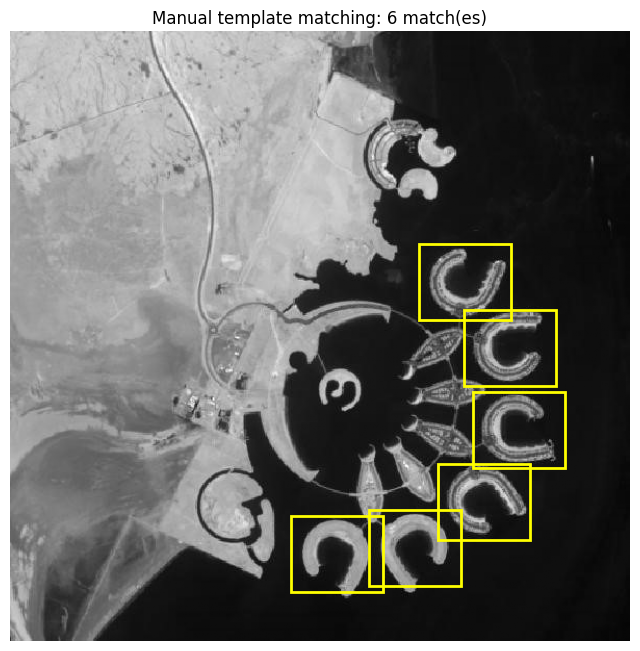

Match scores: [0.963, 0.575, 0.518, 0.498, 0.473, 0.47]


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color
from scipy.signal import fftconvolve
from scipy.ndimage import maximum_filter

source_path = "/content/drive/MyDrive/PCVK_2026/Images/bahrain.jpg"
template_path = "/content/drive/MyDrive/PCVK_2026/Images/bahrain-template.jpg"

source = io.imread(source_path)
template = io.imread(template_path)

if source.ndim == 3:
    source = color.rgb2gray(source[..., :3])
if template.ndim == 3:
    template = color.rgb2gray(template[..., :3])

source = source.astype(np.float32)
template = template.astype(np.float32)
template_height, template_width = template.shape

# Manual normalized cross-correlation at the template's original size
template_centered = template - template.mean()
template_energy = np.sum(template_centered ** 2)

numerator = fftconvolve(
    source,
    template_centered[::-1, ::-1],
    mode="valid",
)

integral = np.pad(
    source.cumsum(axis=0).cumsum(axis=1),
    ((1, 0), (1, 0)),
)
integral_squared = np.pad(
    (source ** 2).cumsum(axis=0).cumsum(axis=1),
    ((1, 0), (1, 0)),
)

window_sum = (
    integral[template_height:, template_width:]
    - integral[:-template_height, template_width:]
    - integral[template_height:, :-template_width]
    + integral[:-template_height, :-template_width]
)
window_sum_squared = (
    integral_squared[template_height:, template_width:]
    - integral_squared[:-template_height, template_width:]
    - integral_squared[template_height:, :-template_width]
    + integral_squared[:-template_height, :-template_width]
)

window_variance = np.maximum(
    window_sum_squared
    - window_sum ** 2 / (template_height * template_width),
    0,
)
denominator = np.sqrt(window_variance * template_energy)

scores = np.divide(
    numerator,
    denominator,
    out=np.zeros_like(numerator, dtype=np.float32),
    where=denominator > 1e-8,
)

# Find local peaks above the score threshold
score_threshold = 0.45
peak_size = (
    max(3, template_height // 2),
    max(3, template_width // 2),
)
local_peaks = scores == maximum_filter(scores, size=peak_size)
ys, xs = np.where(local_peaks & (scores >= score_threshold))

candidates = sorted(
    [(float(scores[y, x]), int(x), int(y)) for y, x in zip(ys, xs)],
    reverse=True,
)

# Keep separated candidates, stopping at the six matches shown in the example
detections = []
minimum_distance = 0.6 * min(template_height, template_width)

for score, x, y in candidates:
    center_x = x + template_width / 2
    center_y = y + template_height / 2

    separated = all(
        np.hypot(
            center_x - (bx + template_width / 2),
            center_y - (by + template_height / 2),
        ) >= minimum_distance
        for _, bx, by in detections
    )

    if separated:
        detections.append((score, x, y))

    if len(detections) == 6:
        break

# Display the detected matches
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(source, cmap="gray")

for score, x, y in detections:
    ax.add_patch(
        plt.Rectangle(
            (x, y),
            template_width,
            template_height,
            fill=False,
            edgecolor="yellow",
            linewidth=2,
        )
    )

ax.set_title(f"Manual template matching: {len(detections)} match(es)")
ax.axis("off")
plt.show()

print("Match scores:", [round(score, 3) for score, x, y in detections])

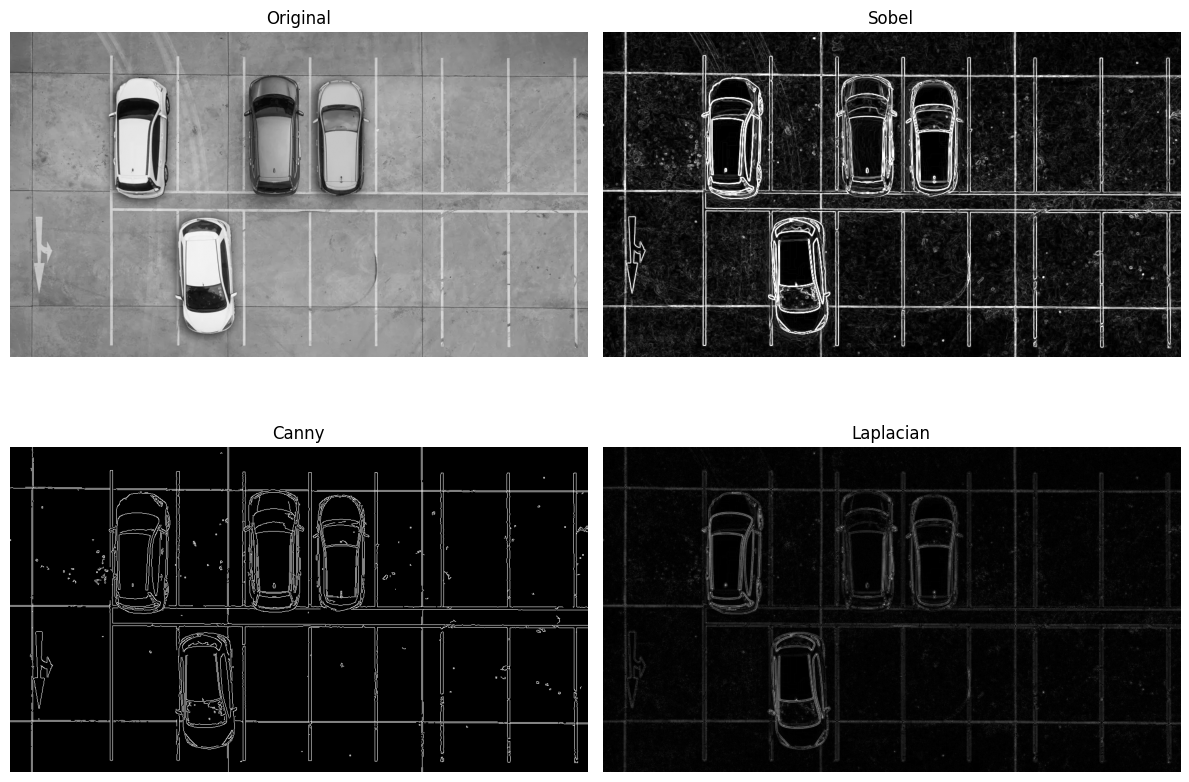

In [9]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/car-park.jpg"
image = cv.imread(image_path, cv.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(image_path)

sobel_x = cv.Sobel(image, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(image, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))

canny = cv.Canny(image, 100, 200)

blurred = cv.GaussianBlur(image, (3, 3), 0)
laplacian = cv.convertScaleAbs(cv.Laplacian(blurred, cv.CV_64F))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
results = [
    ("Original", image),
    ("Sobel", sobel),
    ("Canny", canny),
    ("Laplacian", laplacian),
]

for ax, (title, result) in zip(axes.flat, results):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

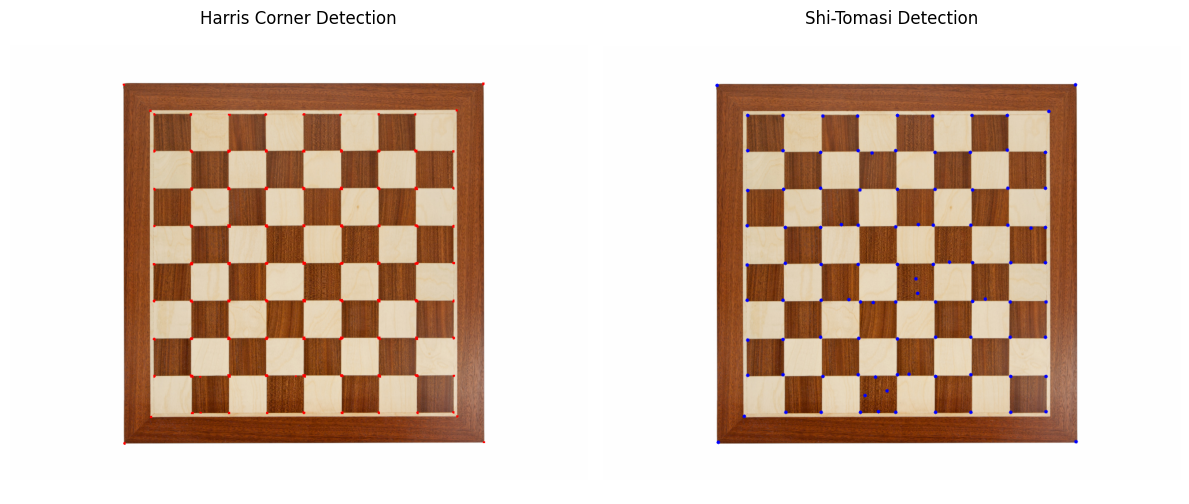

Shi-Tomasi corners detected: 100


In [11]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

image_path = "/content/drive/MyDrive/PCVK_2026/Images/chess-board.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Harris Corner Detection
gray_float = np.float32(gray)
harris_response = cv.cornerHarris(
    gray_float,
    blockSize=2,
    ksize=3,
    k=0.04,
)
harris_response = cv.dilate(harris_response, None)

harris_result = image.copy()
harris_result[harris_response > 0.01 * harris_response.max()] = [0, 0, 255]

# Shi-Tomasi Detection
shi_result = image.copy()
corners = cv.goodFeaturesToTrack(
    gray,
    maxCorners=100,
    qualityLevel=0.03,
    minDistance=20,
    blockSize=5,
    useHarrisDetector=False,
)

if corners is not None:
    for point in corners:
        x, y = point.ravel().astype(int)
        cv.circle(shi_result, (x, y), 3, (255, 0, 0), -1)

# Display both results
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cv.cvtColor(harris_result, cv.COLOR_BGR2RGB))
axes[0].set_title("Harris Corner Detection")
axes[0].axis("off")

axes[1].imshow(cv.cvtColor(shi_result, cv.COLOR_BGR2RGB))
axes[1].set_title("Shi-Tomasi Detection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Shi-Tomasi corners detected:", 0 if corners is None else len(corners))

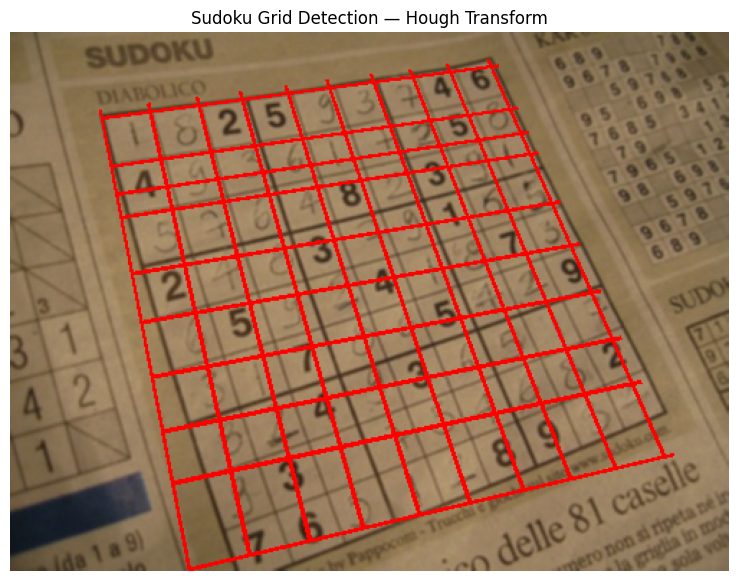

In [14]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/sudoku.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Corners of the large DIABOLICO grid in this 500x375 image:
# top-left, top-right, bottom-right, bottom-left
source_corners = np.float32([
    [62, 54],
    [337, 18],
    [461, 294],
    [124, 374],
])

grid_size = 450
destination_corners = np.float32([
    [0, 0],
    [grid_size - 1, 0],
    [grid_size - 1, grid_size - 1],
    [0, grid_size - 1],
])

transform_matrix = cv.getPerspectiveTransform(
    source_corners, destination_corners
)
rectified = cv.warpPerspective(image, transform_matrix, (grid_size, grid_size))

gray = cv.cvtColor(rectified, cv.COLOR_BGR2GRAY)
blurred = cv.GaussianBlur(gray, (3, 3), 0)

# Canny, dilation, and erosion
edges = cv.Canny(blurred, 40, 120)
kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
dilated = cv.dilate(edges, kernel, iterations=1)
processed = cv.erode(dilated, kernel, iterations=1)

# Hough line detection
hough_lines = cv.HoughLines(processed, 1, np.pi / 180, 130)

vertical_rhos = []
horizontal_rhos = []

if hough_lines is not None:
    for rho, theta in hough_lines[:, 0]:
        # Convert vertical lines to a consistent rho direction
        if theta < np.deg2rad(8):
            vertical_rhos.append(rho)
        elif theta > np.pi - np.deg2rad(8):
            vertical_rhos.append(-rho)
        elif abs(theta - np.pi / 2) < np.deg2rad(8):
            horizontal_rhos.append(rho)

def merge_rho_values(values, tolerance=10):
    values = sorted(v for v in values if -20 <= v <= grid_size + 20)
    groups = []

    for value in values:
        if groups and abs(value - np.mean(groups[-1])) < tolerance:
            groups[-1].append(value)
        else:
            groups.append([value])

    return [float(np.mean(group)) for group in groups]

vertical_positions = merge_rho_values(vertical_rhos)
horizontal_positions = merge_rho_values(horizontal_rhos)

# Snap Hough detections to the ten lines of the 9x9 Sudoku grid
expected_positions = np.linspace(0, grid_size - 1, 10)

def snap_grid_lines(detected_positions):
    chosen = []
    unused = detected_positions.copy()

    for expected in expected_positions:
        nearby = [p for p in unused if abs(p - expected) <= 25]

        if nearby:
            position = min(nearby, key=lambda p: abs(p - expected))
            unused.remove(position)
            chosen.append(int(round(np.clip(position, 0, grid_size - 1))))
        else:
            chosen.append(int(round(expected)))

    return chosen

vertical_positions = snap_grid_lines(vertical_positions)
horizontal_positions = snap_grid_lines(horizontal_positions)

# Draw the detected grid lines on a mask, then map them back to the original image
line_mask = np.zeros((grid_size, grid_size), dtype=np.uint8)

for x in vertical_positions:
    cv.line(line_mask, (x, 0), (x, grid_size - 1), 255, 2)

for y in horizontal_positions:
    cv.line(line_mask, (0, y), (grid_size - 1, y), 255, 2)

inverse_matrix = np.linalg.inv(transform_matrix)
original_height, original_width = image.shape[:2]
lines_on_original = cv.warpPerspective(
    line_mask,
    inverse_matrix,
    (original_width, original_height),
)

result = image.copy()
result[lines_on_original > 0] = (0, 0, 255)

plt.figure(figsize=(10, 7))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Sudoku Grid Detection — Hough Transform")
plt.axis("off")
plt.show()

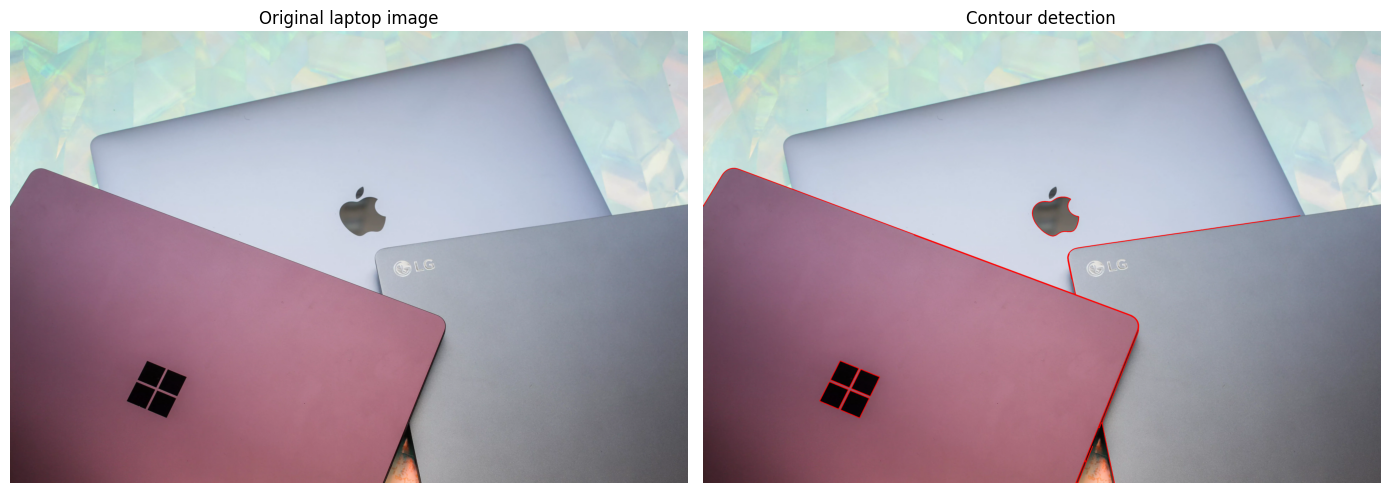

In [18]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/laptop.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
blurred = cv.GaussianBlur(gray, (5, 5), 0)
edges = cv.Canny(blurred, 50, 150)

kernel = cv.getStructuringElement(cv.MORPH_RECT, (5, 5))
closed_edges = cv.morphologyEx(edges, cv.MORPH_CLOSE, kernel)

contours, hierarchy = cv.findContours(
    closed_edges,
    cv.RETR_EXTERNAL,
    cv.CHAIN_APPROX_SIMPLE,
)

result = image.copy()
large_contours = [
    contour for contour in contours
    if cv.contourArea(contour) > 10000
]
cv.drawContours(result, large_contours, -1, (0, 0, 255), 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
axes[0].set_title("Original laptop image")
axes[1].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
axes[1].set_title("Contour detection")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

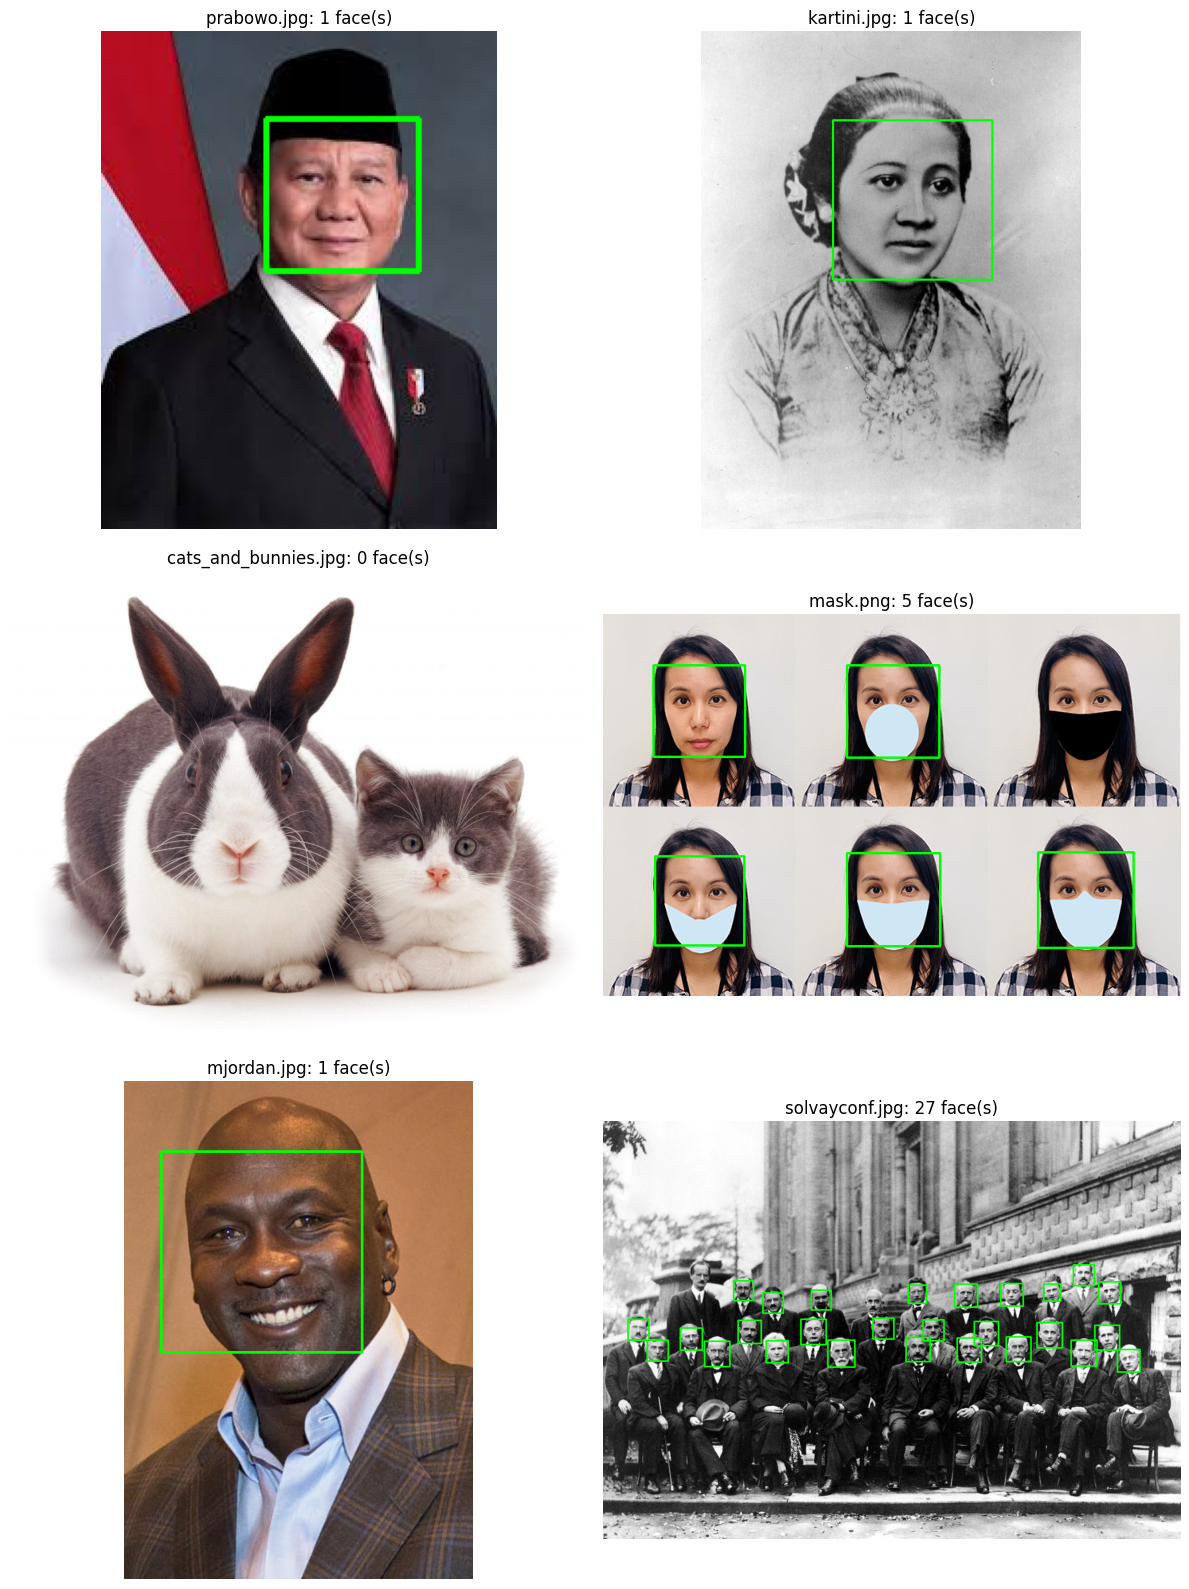

In [19]:
from pathlib import Path

image_paths = [
    "/content/drive/MyDrive/PCVK_2026/Images/prabowo.jpg",
    "/content/drive/MyDrive/PCVK_2026/Images/kartini.jpg",
    "/content/drive/MyDrive/PCVK_2026/Images/cats_and_bunnies.jpg",
    "/content/drive/MyDrive/PCVK_2026/Images/mask.png",
    "/content/drive/MyDrive/PCVK_2026/Images/mjordan.jpg",
    "/content/drive/MyDrive/PCVK_2026/Images/solvayconf.jpg",
]

cascade_path = (
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_frontalface_alt.xml"
)
face_cascade = cv.CascadeClassifier(cascade_path)

if face_cascade.empty():
    face_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalface_alt.xml"
    )

fig, axes = plt.subplots(3, 2, figsize=(12, 16))

for ax, image_path in zip(axes.flat, image_paths):
    image = cv.imread(image_path)

    if image is None:
        ax.set_title(f"Could not load: {Path(image_path).name}")
        ax.axis("off")
        continue

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(20, 20),
    )

    for x, y, w, h in faces:
        cv.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)

    ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(f"{Path(image_path).name}: {len(faces)} face(s)")
    ax.axis("off")

plt.tight_layout()
plt.show()

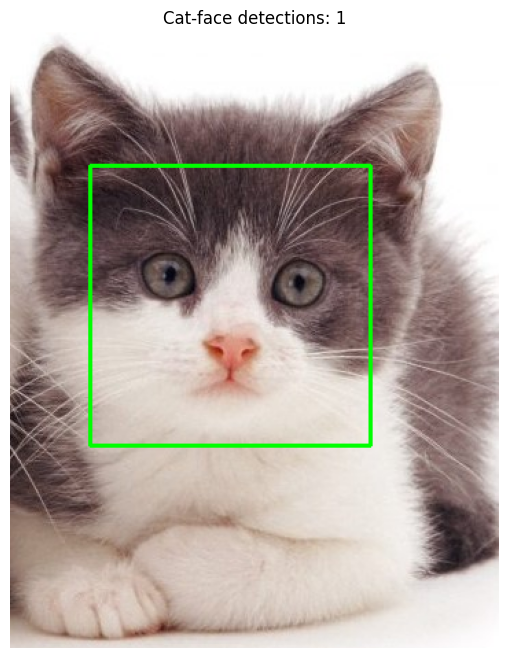

In [20]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/cat2_templatejpg.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

cat_cascade_path = (
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_frontalcatface.xml"
)
cat_cascade = cv.CascadeClassifier(cat_cascade_path)

if cat_cascade.empty():
    cat_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalcatface.xml"
    )

if cat_cascade.empty():
    raise FileNotFoundError("Could not load haarcascade_frontalcatface.xml")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
cat_faces = cat_cascade.detectMultiScale(
    gray,
    scaleFactor=1.05,
    minNeighbors=3,
    minSize=(30, 30),
)

for x, y, w, h in cat_faces:
    cv.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(7, 8))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title(f"Cat-face detections: {len(cat_faces)}")
plt.axis("off")
plt.show()

Eye regions detected: 2


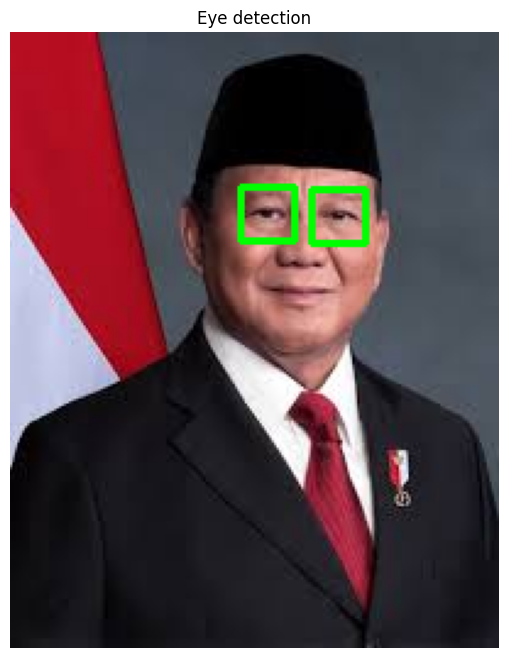

In [22]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

image_path = "/content/drive/MyDrive/PCVK_2026/Images/prabowo.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

cascade_dir = "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"

face_cascade = cv.CascadeClassifier(
    cascade_dir + "haarcascade_frontalface_alt.xml"
)
if face_cascade.empty():
    face_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalface_alt.xml"
    )

eye_cascades = [
    cv.CascadeClassifier(cascade_dir + "haarcascade_eye.xml"),
    cv.CascadeClassifier(cascade_dir + "haarcascade_eye_tree_eyeglasses.xml"),
]

# Use OpenCV's cascades if the files are not in the Drive folder
if eye_cascades[0].empty():
    eye_cascades[0] = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_eye.xml"
    )
if eye_cascades[1].empty():
    eye_cascades[1] = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_eye_tree_eyeglasses.xml"
    )

faces = face_cascade.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30)
)

# Use the largest detected face
if len(faces) > 0:
    x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
    upper_face = gray[y:y + int(h * 0.65), x:x + w]
else:
    # Fallback region if the face cascade does not find a face
    x, y, w, h = 0, 0, gray.shape[1], int(gray.shape[0] * 0.65)
    upper_face = gray[y:y + h, x:x + w]

# Try both eye cascades with more sensitive settings
candidates = []
for eye_cascade in eye_cascades:
    if eye_cascade.empty():
        continue

    found = eye_cascade.detectMultiScale(
        upper_face,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(8, 8),
        maxSize=(max(20, w // 2), max(15, h // 3)),
    )

    for ex, ey, ew, eh in found:
        candidates.append((x + ex, y + ey, ew, eh))

# Remove duplicate detections of the same eye
unique_eyes = []
for eye in candidates:
    ex, ey, ew, eh = eye
    center_x = ex + ew / 2
    center_y = ey + eh / 2

    duplicate = False
    for ux, uy, uw, uh in unique_eyes:
        other_x = ux + uw / 2
        other_y = uy + uh / 2
        if np.hypot(center_x - other_x, center_y - other_y) < 10:
            duplicate = True
            break

    if not duplicate:
        unique_eyes.append(eye)

# Choose a horizontally paired set of eye detections when possible
eye_pair = []
best_pair_score = float("inf")

for i in range(len(unique_eyes)):
    for j in range(i + 1, len(unique_eyes)):
        e1 = unique_eyes[i]
        e2 = unique_eyes[j]

        c1x, c1y = e1[0] + e1[2] / 2, e1[1] + e1[3] / 2
        c2x, c2y = e2[0] + e2[2] / 2, e2[1] + e2[3] / 2

        horizontal_distance = abs(c1x - c2x)
        vertical_difference = abs(c1y - c2y)

        if horizontal_distance > w * 0.15 and vertical_difference < h * 0.25:
            score = vertical_difference + abs((c1x + c2x) / 2 - (x + w / 2))
            if score < best_pair_score:
                best_pair_score = score
                eye_pair = [e1, e2]

# Draw the paired detections, or the available candidates if no pair was found
result = image.copy()
eyes_to_draw = eye_pair if eye_pair else unique_eyes

for ex, ey, ew, eh in eyes_to_draw:
    cv.rectangle(result, (ex, ey), (ex + ew, ey + eh), (0, 255, 0), 2)

print("Eye regions detected:", len(eyes_to_draw))

plt.figure(figsize=(7, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Eye detection")
plt.axis("off")
plt.show()

Face at (256, 25): 0 smile detection(s)
Face at (23, 25): 0 smile detection(s)
Face at (383, 47): 0 smile detection(s)
Face at (520, 44): 0 smile detection(s)
Face at (505, 168): 0 smile detection(s)
Face at (253, 180): 1 smile detection(s)
Face at (140, 172): 0 smile detection(s)
Face at (19, 179): 1 smile detection(s)
Face at (377, 173): 1 smile detection(s)


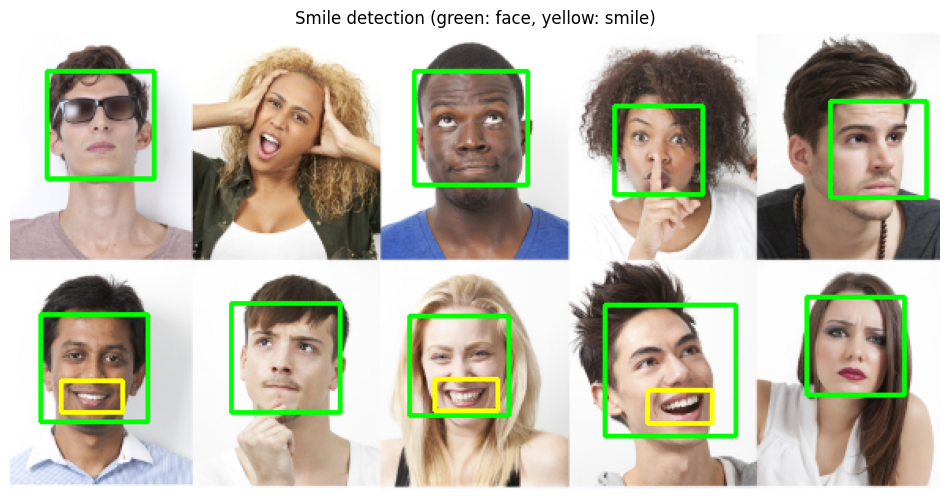

In [24]:
import cv2 as cv
import matplotlib.pyplot as plt

image_path = "/content/drive/MyDrive/PCVK_2026/Images/people.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

face_cascade = cv.CascadeClassifier(
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_frontalface_alt.xml"
)
smile_cascade = cv.CascadeClassifier(
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_smile.xml"
)

if face_cascade.empty():
    face_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalface_alt.xml"
    )
if smile_cascade.empty():
    smile_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_smile.xml"
    )

faces = face_cascade.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(25, 25)
)
result = image.copy()

for x, y, w, h in faces:
    cv.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # Search the lower part of the face for a smile
    mouth_y = int(h * 0.40)
    mouth_region = gray[y + mouth_y:y + h, x:x + w]

    smiles = smile_cascade.detectMultiScale(
        mouth_region,
        scaleFactor=1.2,
        minNeighbors=8,
        minSize=(max(10, w // 8), max(8, h // 12)),
    )

    for sx, sy, sw, sh in smiles:
        cv.rectangle(
            result,
            (x + sx, y + mouth_y + sy),
            (x + sx + sw, y + mouth_y + sy + sh),
            (0, 255, 255),
            2,
        )

    print(f"Face at ({x}, {y}): {len(smiles)} smile detection(s)")

plt.figure(figsize=(12, 7))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Smile detection (green: face, yellow: smile)")
plt.axis("off")
plt.show()

<IPython.core.display.Javascript object>

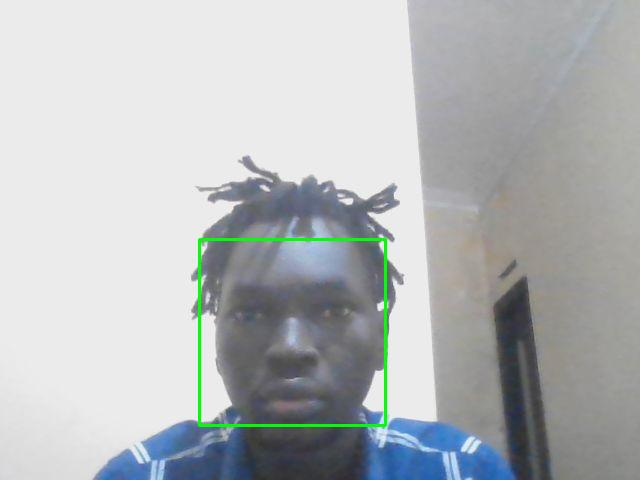

Face tracking stopped.


In [27]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image as PILImage
import io

display(Javascript("""
async function startCamera() {
  const video = document.createElement('video');
  video.style.width = '480px';
  video.autoplay = true;
  video.playsInline = true;
  video.srcObject = await navigator.mediaDevices.getUserMedia({video: true});
  await video.play();
  document.body.appendChild(video);
  window.faceTrackVideo = video;
}
async function captureFrame() {
  const video = window.faceTrackVideo;
  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video, 0, 0);
  return canvas.toDataURL('image/jpeg', 0.8).split(',')[1];
}
async function stopCamera() {
  const video = window.faceTrackVideo;
  if (video && video.srcObject) {
    video.srcObject.getTracks().forEach(track => track.stop());
    video.remove();
  }
}
"""))

face_cascade = cv.CascadeClassifier(
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_frontalface_alt.xml"
)
if face_cascade.empty():
    face_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalface_alt.xml"
    )

eval_js("startCamera()")
display_handle = display(Image(data=b""), display_id=True)

try:
    for _ in range(300):
        frame_data = b64decode(eval_js("captureFrame()"))
        frame = cv.imdecode(
            np.frombuffer(frame_data, np.uint8),
            cv.IMREAD_COLOR,
        )
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(
            gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
        )

        for x, y, w, h in faces:
            cv.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

        frame_rgb = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
        buffer = io.BytesIO()
        PILImage.fromarray(frame_rgb).save(buffer, format="JPEG")
        display_handle.update(Image(data=buffer.getvalue()))

except KeyboardInterrupt:
    print("Face tracking stopped.")

finally:
    eval_js("stopCamera()")

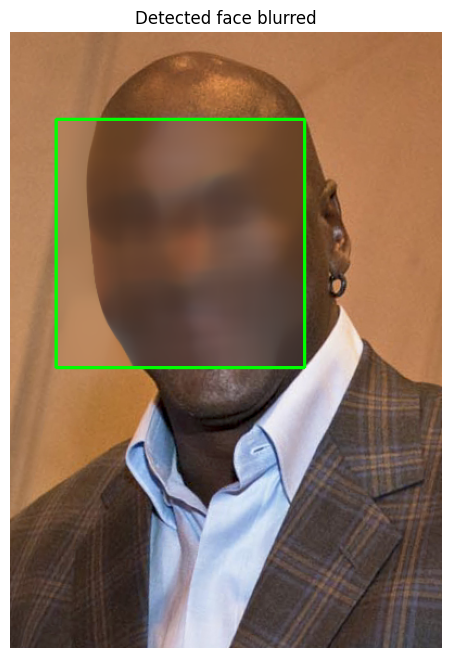

In [29]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/mjordan.jpg"
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
face_cascade = cv.CascadeClassifier(
    "/content/drive/MyDrive/PCVK_2026/Images/haarcascades/"
    "haarcascade_frontalface_alt.xml"
)
if face_cascade.empty():
    face_cascade = cv.CascadeClassifier(
        cv.data.haarcascades + "haarcascade_frontalface_alt.xml"
    )

faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(30, 30))
result = image.copy()

for x, y, w, h in faces:
    face = result[y:y+h, x:x+w]
    kernel_size = min(51, min(w, h))

    if kernel_size % 2 == 0:
        kernel_size -= 1

    if kernel_size >= 3:
        result[y:y+h, x:x+w] = cv.medianBlur(face, kernel_size)

    cv.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Detected face blurred")
plt.axis("off")
plt.show()

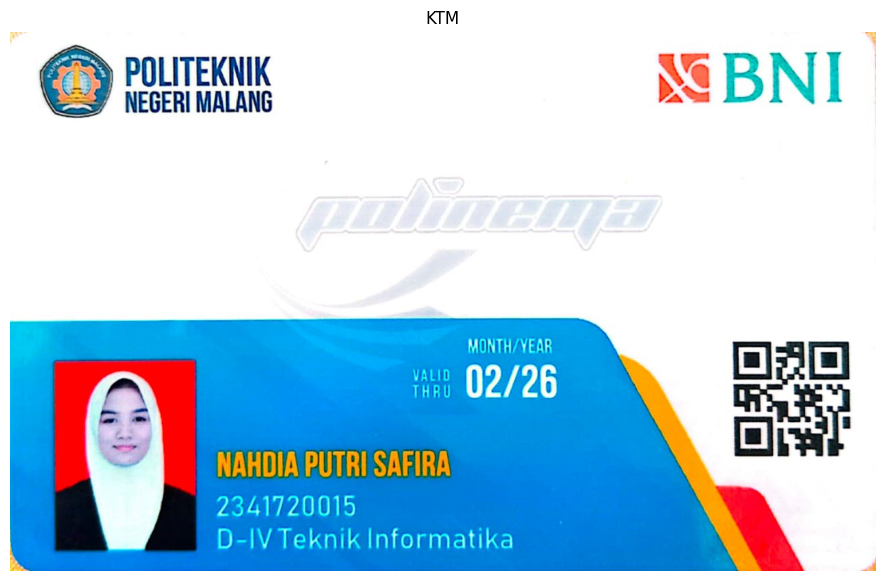

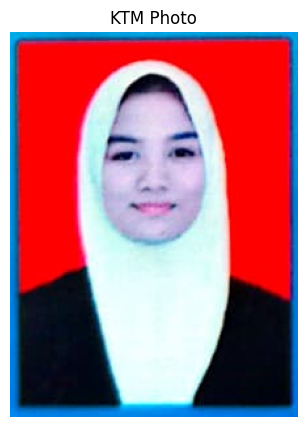

In [32]:
image_path = "/content/drive/MyDrive/PCVK_2026/Images/KTM Baru.jpg"
ktm = cv.imread(image_path)

if ktm is None:
    raise FileNotFoundError(image_path)

# Display the full KTM
plt.figure(figsize=(12, 7))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title("KTM")
plt.axis("off")
plt.show()

# Crop and display the portrait photo on the KTM
photo = ktm[480:775, 60:280]

plt.figure(figsize=(4, 5))
plt.imshow(cv.cvtColor(photo, cv.COLOR_BGR2RGB))
plt.title("KTM Photo")
plt.axis("off")
plt.show()

Good matches: 51


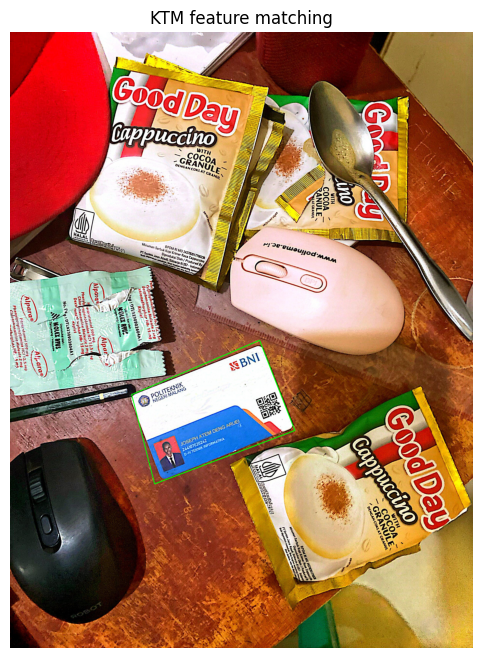

In [34]:
ktm_path = "/content/drive/MyDrive/PCVK_2026/Images/KTM Baru.jpg"
scene_path = "/content/drive/MyDrive/PCVK_2026/Images/KTM_scene.jpeg"

template = cv.imread(ktm_path)
scene = cv.imread(scene_path)

if template is None:
    raise FileNotFoundError(ktm_path)
if scene is None:
    raise FileNotFoundError(scene_path)

template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

orb = cv.ORB_create(nfeatures=3000)
keypoints_template, descriptors_template = orb.detectAndCompute(
    template_gray, None
)
keypoints_scene, descriptors_scene = orb.detectAndCompute(scene_gray, None)

if descriptors_template is None or descriptors_scene is None:
    raise ValueError("ORB could not find enough features in the KTM or scene image.")

matches = cv.BFMatcher(cv.NORM_HAMMING).knnMatch(
    descriptors_template,
    descriptors_scene,
    k=2,
)

good_matches = [
    first for first, second in matches
    if first.distance < 0.75 * second.distance
]

result = scene.copy()

if len(good_matches) >= 4:
    source_points = np.float32([
        keypoints_template[m.queryIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    destination_points = np.float32([
        keypoints_scene[m.trainIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    homography, inliers = cv.findHomography(
        source_points,
        destination_points,
        cv.RANSAC,
        5.0,
    )

    if homography is not None:
        h, w = template_gray.shape
        corners = np.float32([
            [0, 0],
            [w - 1, 0],
            [w - 1, h - 1],
            [0, h - 1],
        ]).reshape(-1, 1, 2)

        projected_corners = cv.perspectiveTransform(corners, homography)
        cv.polylines(
            result,
            [np.int32(projected_corners)],
            True,
            (0, 255, 0),
            3,
        )
else:
    print("Not enough good matches:", len(good_matches))

print("Good matches:", len(good_matches))
plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("KTM feature matching")
plt.axis("off")
plt.show()

In [17]:
from pathlib import Path

dataset_path = Path("/content/drive/MyDrive/PCVK_2026/dataset")
characters = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

for character in characters:
    (dataset_path / "training" / character).mkdir(
        parents=True, exist_ok=True
    )

(dataset_path / "testing" / "KTM_test_01").mkdir(
    parents=True, exist_ok=True
)

print("Training and testing folders created.")

Training and testing folders created.


## PRACTICAL ASSIGNMENT

In [18]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import os
import pickle
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    ZeroPadding2D,
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

DATA_PATH = "/content/drive/MyDrive/PCVK_2026"

In [20]:
import os
import pickle
import random
import cv2 as cv
import numpy as np
from pathlib import Path

DATADIR = Path("/content/drive/MyDrive/PCVK_2026/dataset/training")
DATA_PATH = Path("/content/drive/MyDrive/PCVK_2026")

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
width = height = 100

class_names = sorted(
    folder.name
    for folder in DATADIR.iterdir()
    if folder.is_dir()
    and any(
        file.suffix.lower() in valid_extensions
        for file in folder.iterdir()
    )
)

if not class_names:
    raise FileNotFoundError(f"No class folders with images found in {DATADIR}")

training_data = []

for class_number, class_name in enumerate(class_names):
    class_folder = DATADIR / class_name

    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() not in valid_extensions:
            continue

        image = cv.imread(str(image_path), cv.IMREAD_GRAYSCALE)
        if image is None:
            continue

        resized = cv.resize(image, (width, height))
        training_data.append((resized, class_number))

if not training_data:
    raise ValueError("No readable training images were found.")

random.shuffle(training_data)

X = np.array([item[0] for item in training_data], dtype=np.uint8)
Y = np.array([item[1] for item in training_data], dtype=np.int64)
X = X.reshape(-1, height, width, 1)

DATA_PATH.mkdir(parents=True, exist_ok=True)

with open(DATA_PATH / "X.pickle", "wb") as file:
    pickle.dump(X, file)

with open(DATA_PATH / "Y.pickle", "wb") as file:
    pickle.dump(Y, file)

with open(DATA_PATH / "kelas.pickle", "wb") as file:
    pickle.dump(class_names, file)

print("Saved training files to:", DATA_PATH)
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Classes:", class_names)

Saved training files to: /content/drive/MyDrive/PCVK_2026
X shape: (177, 100, 100, 1)
Y shape: (177,)
Classes: ['0', '1', '2', '4', '7', 'A', 'B', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U']


In [21]:
with open(os.path.join(DATA_PATH, "X.pickle"), "rb") as file:
    X = pickle.load(file)

with open(os.path.join(DATA_PATH, "Y.pickle"), "rb") as file:
    Y = pickle.load(file)

with open(os.path.join(DATA_PATH, "kelas.pickle"), "rb") as file:
    kelas = pickle.load(file)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Classes:", kelas)

X shape: (177, 100, 100, 1)
Y shape: (177,)
Classes: ['0', '1', '2', '4', '7', 'A', 'B', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U']


In [22]:
width, height = 100, 100

X = np.asarray(X, dtype=np.float32) / 255.0
Y = to_categorical(Y)

jumlah_kelas = Y.shape[1]

print("Number of classes:", jumlah_kelas)
print("Input shape:", X.shape)
print("Label shape:", Y.shape)

Number of classes: 24
Input shape: (177, 100, 100, 1)
Label shape: (177, 24)


In [23]:
inputs = Input(shape=(width, height, 1))

conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(
    16, (5, 5), strides=(1, 1), activation="relu"
)(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(
    32, (3, 3), strides=(1, 1), activation="relu"
)(conv_layer)
conv_layer = Conv2D(
    32, (3, 3), strides=(1, 1), activation="relu"
)(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(
    64, (3, 3), strides=(1, 1), activation="relu"
)(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation="relu")(flaten)
fc_layer = Dense(64, activation="relu")(fc_layer)
outputs = Dense(jumlah_kelas, activation="softmax")(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d_1                │ (None, 104, 104, 1)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 100, 100, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 28224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     7,225,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,276,408 (27.76 MB)

 Trainable params: 7,276,408 (27.76 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

In [25]:
riwayat = model.fit(
    X,
    Y,
    epochs=20,
    verbose=1,
    validation_split=0.2,
)

model.save(os.path.join(DATA_PATH, "anpr.keras"))

print("Training accuracy:", riwayat.history["accuracy"][-1])
print("Validation accuracy:", riwayat.history["val_accuracy"][-1])

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 524ms/step - accuracy: 0.0355 - loss: 3.1824 - val_accuracy: 0.0278 - val_loss: 3.1847
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 475ms/step - accuracy: 0.0709 - loss: 3.1520 - val_accuracy: 0.0000e+00 - val_loss: 3.1808
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 438ms/step - accuracy: 0.0567 - loss: 3.1241 - val_accuracy: 0.0000e+00 - val_loss: 3.1700
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 432ms/step - accuracy: 0.0567 - loss: 3.0855 - val_accuracy: 0.0000e+00 - val_loss: 3.1644
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 593ms/step - accuracy: 0.0851 - loss: 3.0311 - val_accuracy: 0.0278 - val_loss: 3.1525
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 763ms/step - accuracy: 0.1135 - loss: 2.9734 - val_accuracy: 0.0556 - val_loss: 3.0886
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 436ms/step - accuracy: 0.1915 - loss: 2.8868 - val_accuracy: 0.2222 - val_loss: 2.9441
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 437ms/step - accuracy: 0.2979 - loss: 2.7687 - val_accuracy: 0.2222

In [40]:
from pathlib import Path
import pickle
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, classification_report

# Model and class labels are saved in PCVK_2026
DATA_PATH = Path("/content/drive/MyDrive/PCVK_2026")
MODEL_PATH = DATA_PATH / "anpr.keras"
CLASSES_PATH = DATA_PATH / "kelas.pickle"

# Testing data is inside PCVK_2026/dataset/testing
TEST_PARENT = DATA_PATH / "dataset" / "testing"

# The ZIP may have extracted into a nested ktm_testing_dataset folder
nested_test_dir = TEST_PARENT / "ktm_testing_dataset"
TEST_DIR = nested_test_dir if nested_test_dir.exists() else TEST_PARENT

if not TEST_DIR.exists():
    raise FileNotFoundError(f"Testing folder not found: {TEST_DIR}")

print("Using testing folder:", TEST_DIR)
print("Contents:", [item.name for item in TEST_DIR.iterdir()])

# Load the trained model and training class order
model = load_model(MODEL_PATH)

with open(CLASSES_PATH, "rb") as file:
    kelas = [str(label) for label in pickle.load(file)]

class_to_index = {label: index for index, label in enumerate(kelas)}

# Read test images. Each image's parent folder name is its true label.
X_test = []
y_true = []
image_names = []
skipped_classes = []

for class_folder in sorted(TEST_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    true_label = class_folder.name

    if true_label not in class_to_index:
        skipped_classes.append(true_label)
        continue

    for image_path in sorted(class_folder.iterdir()):
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print("Could not read:", image_path)
            continue

        image = cv2.resize(image, (100, 100))
        X_test.append(image.reshape(100, 100, 1) / 255.0)
        y_true.append(class_to_index[true_label])
        image_names.append(image_path.name)

if not X_test:
    raise ValueError(
        "No test images found. TEST_DIR should contain class folders "
        "such as A, B, 0, or 1."
    )

X_test = np.array(X_test, dtype=np.float32)
y_true = np.array(y_true)

# Predict and calculate test accuracy
probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

correct = int(np.sum(y_true == y_pred))
total = len(y_true)

print(f"\nTest accuracy: {correct / total * 100:.2f}%")
print(f"Correct predictions: {correct} / {total}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(kelas)),
    target_names=kelas,
    zero_division=0
))

print("\nIndividual predictions:")
for name, actual, predicted in zip(image_names, y_true, y_pred):
    print(f"{name}: actual={kelas[actual]}, predicted={kelas[predicted]}")

if skipped_classes:
    print("\nSkipped folders for classes not in training:", skipped_classes)

Using testing folder: /content/drive/MyDrive/PCVK_2026/dataset/testing/ktm_testing_dataset
Contents: ['U', 'O', 'T', 'N', 'L', 'E', 'S', 'I', 'P', 'M', 'G', 'H', 'K', 'R', 'D', 'B', '2', '0', '1', 'A']



Test accuracy: 16.33%
Correct predictions: 16 / 98

Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.00      0.00      0.00         4
           2       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         0
           7       0.00      0.00      0.00         0
           A       0.18      0.60      0.28        15
           B       0.00      0.00      0.00         6
           D       0.00      0.00      0.00         2
           E       0.00      0.00      0.00         7
           F       0.00      0.00      0.00         0
           G       0.00      0.00      0.00         4
           H       0.00      0.00      0.00         3
           I       0.24      0.44      0.31         9
           J       0.00      0.00      0.00         0
           K       0.00      0.00      0.00         6
           L       0.00      0.00      0.00         3
     